# Mini-proyecto 6: agente de operación Oracle con herramientas MCP, LangChain y Ollama

**Autores:** José Luis Realpe M., Alejandra Forero, Santiago Aristizabal, Sandra Orozco
**Curso:** Procesamiento de Lenguaje Natural — Maestría en IA Aplicada, Universidad Icesi
**Basado en:** notebooks guía de la Sesión 6 (`1-herramientas-y-agentes-con-ollama`, `2-mcp-langchain-ollama`, `3-chatbot-con-mcp-y-gradio`)

---

## 1. Planteamiento

### El problema

Un administrador de bases de datos (DBA) responde todos los días preguntas operativas como *¿cuánto le queda al tablespace USERS?*,
*¿terminó bien el backup del fin de semana?*, *¿cuál es el RPO ahora mismo?* o *¿qué pasó con la FRA el sábado?*. La información
existe en vistas del diccionario de Oracle (`DBA_DATA_FILES`, `V$RECOVERY_FILE_DEST`, `V$RMAN_BACKUP_JOB_DETAILS`, Statspack)
y en tableros de monitoreo, pero hay que saber dónde buscar, cruzar varias fuentes y hacer cuentas (tasas de crecimiento,
proyecciones, horas de exposición). Queremos un **asistente en lenguaje natural** que reciba la pregunta, decida qué consultar,
calcule lo que haga falta y responda con cifras verificables.

Los notebooks guía resuelven dos tareas de juguete (una calculadora y el clima) con un modelo local y el protocolo MCP. Aquí
cambiamos el dominio por uno real y medimos lo que el guía no mide: **qué tan confiable es un LLM local para elegir y usar
herramientas** cuando hay ocho herramientas parecidas, preguntas que exigen encadenar dos de ellas y preguntas trampa.

### Por qué MCP

Sin MCP, cada herramienta vive pegada a la aplicación que la usa (notebook 1 del guía). Con MCP (Model Context Protocol) las
capacidades se exponen desde un **servidor** con un contrato estándar (tools, resources, prompts) y cualquier **host** las consume:
este notebook, una interfaz Gradio, Claude Desktop o un agente en producción. Para un equipo de DBA eso significa escribir una
sola vez las consultas de capacidad y backups y reutilizarlas con cualquier modelo o cliente.

### Datos

Un **repositorio operativo sintético** en SQLite con 90 días de métricas de cuatro bases con perfiles distintos (18c SE2
single-instance, 19c EE primaria con Data Guard, su standby y un RAC de dos nodos). Es sintético por dos razones: no exponer
datos de producción y poder **plantar escenarios con respuesta conocida** (un tablespace que se acelera, una FRA que se llena,
un backup que falla) contra los que se califica al agente. Todo se genera con semilla fija desde `data/generar_datos.py`.

### Preguntas y experimentos

| # | Pregunta | Experimento |
|---|---|---|
| 1 | ¿Cambia el tamaño del modelo la calidad del uso de herramientas? | 30 preguntas × 3 modelos locales (3B, 9B, 14B) |
| 2 | ¿Cuánto control hace falta para que la herramienta se use bien? | Modos autónomo, guiado y determinístico |
| 3 | ¿Más herramientas disponibles confunden al modelo? | 8 herramientas MCP frente a 8 MCP + 8 distractoras |
| 4 | ¿Cuánto importa la descripción que ve el LLM? | Mismo servidor con docstrings completos y mínimos |
| 5 | ¿Qué cuesta el transporte MCP? | Latencia stdio frente a streamable HTTP |

### Hipótesis

1. Los modelos de 9B y 14B eligen la herramienta correcta y arman bien los argumentos con más frecuencia que el de 3B, y la
   brecha se amplía en las preguntas que encadenan dos herramientas.
2. El modo determinístico maximiza el uso de la herramienta correcta en preguntas simples, pero falla en las compuestas y en
   las trampa, donde el agente autónomo decide mejor.
3. Agregar herramientas distractoras baja la tasa de herramienta correcta sobre todo en el modelo de 3B.
4. Con descripciones mínimas la tasa de herramienta correcta cae de forma marcada en todos los modelos.
5. La latencia del transporte es despreciable frente a la del LLM: la elección entre stdio y HTTP es de despliegue, no de rendimiento.

### Qué cambia respecto a los notebooks guía

| Notebook guía | Este notebook |
|---|---|
| Dos herramientas (calculadora, clima) | Ocho herramientas de un dominio real, con argumentos de varios tipos y validación |
| Solo *tools* | *Tools*, un *resource* (catálogo de datos) y un *prompt* (plantilla de revisión diaria) |
| Un modelo (`llama3.2:3b`) | Tres modelos comparados |
| Evaluación leyendo una respuesta | Banco de 30 preguntas con respuesta conocida y tres métricas automáticas |
| Modos autónomo/guiado/determinístico mostrados | Los tres modos medidos sobre el mismo banco |
| Servidor sin control de acceso | Base de datos abierta en solo lectura y SQL con autorizador |
| Sin EDA | EDA de series operativas con los escenarios plantados |

## 2. Entorno

El notebook se ejecuta **en local** (macOS con Apple Silicon o Linux) con Ollama. Colab no sirve bien aquí porque los
experimentos tardan entre 60 y 90 minutos y necesitan tres modelos descargados. Pasos previos, en una terminal:

```bash
pip install -r requirements.txt
ollama pull llama3.2:3b && ollama pull qwen3.5:9b && ollama pull qwen3:14b
ollama serve          # si no está corriendo como servicio
```

Las celdas marcadas con la etiqueta `ollama` necesitan el modelo; el resto (datos, EDA, servidor, cliente MCP, transporte)
corre sin él. Los resultados de los experimentos se guardan fila a fila en `resultados/experimentos.csv`, así que si la
sesión se interrumpe se reanuda donde iba.

In [1]:
import warnings, os, sys, json, time, asyncio, subprocess, sqlite3
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.dates as mdates
from langchain_ollama import ChatOllama

ROOT = Path.cwd()
assert (ROOT / 'mcp_servers' / 'oracle_ops_mcp_server.py').exists(), 'Ejecuta el notebook desde la carpeta del proyecto'
sys.path.insert(0, str(ROOT))
for d in ('data', 'resultados', 'figuras'):
    (ROOT / d).mkdir(exist_ok=True)

# Paleta y estilo únicos para todas las figuras
AZUL, NARANJA, VERDE, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#898781'
mpl.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e1e0d9', 'grid.linewidth': 0.8, 'axes.titleweight': 'bold', 'font.size': 10})

QUICK_MODE = False         # True: 1 modelo y 10 preguntas por configuración, para verificar que todo funciona (~10 min)
MODELOS = ['llama3.2:3b'] if QUICK_MODE else ['llama3.2:3b', 'qwen3.5:9b', 'qwen3:14b']

def crear_llm(nombre):
    # Los Qwen3 traen modo de razonamiento ('thinking') por defecto: alarga cada respuesta y puede
    # interferir con las llamadas a herramientas. Se desactiva solo para esa familia.
    extra = {'reasoning': False} if nombre.startswith('qwen3') else {}
    return ChatOllama(model=nombre, temperature=0, **extra)
print(f'Proyecto: {ROOT} | QUICK_MODE={QUICK_MODE} | modelos: {MODELOS}')

Proyecto: /Users/joseluis/Documents/Maestria_IA_Aplicada/Semestre_III/NLP/Sesion6 | QUICK_MODE=False | modelos: ['llama3.2:3b', 'qwen3.5:9b', 'qwen3:14b']


In [2]:
# Verificación de Ollama y de los modelos descargados
import httpx
try:
    tags = httpx.get('http://127.0.0.1:11434/api/tags', timeout=5).json()
    disponibles = sorted(m['name'] for m in tags.get('models', []))
    print('Ollama activo. Modelos locales:', disponibles)
    faltan = [m for m in MODELOS if m not in disponibles]
    if faltan:
        print('FALTAN (ollama pull ...):', faltan)
except Exception as exc:
    print('Ollama no responde en 11434:', exc)

Ollama activo. Modelos locales: ['bge-m3:latest', 'gemma3:12b', 'gemma4:12b', 'hermes-local:latest', 'llama3.2:3b', 'mistral-small:24b', 'nomic-embed-text:latest', 'qwen3-embedding:0.6b', 'qwen3-embedding:4b', 'qwen3-embedding:8b', 'qwen3.5:9b', 'qwen3.6:27b', 'qwen3:14b', 'snowflake-arctic-embed2:latest']


## 3. Datos: el repositorio operativo

`data/generar_datos.py` produce `data/oracle_ops.db` con cinco tablas que imitan lo que un DBA recolecta con vistas base y
sin Diagnostics Pack:

| Tabla | Granularidad | Fuente real que imita |
|---|---|---|
| `bases` | una fila por base | `V$DATABASE`, `V$INSTANCE` |
| `tablespace_hist` | un snapshot diario por tablespace | `DBA_DATA_FILES` + `DBA_FREE_SPACE` |
| `fra_hist` | un snapshot por hora | `V$RECOVERY_FILE_DEST`, `V$RECOVERY_AREA_USAGE` |
| `rman_jobs` | un job por backup | `V$RMAN_BACKUP_JOB_DETAILS` |
| `snapshot_waits` | top de esperas cada 6 h | `STATS$SYSTEM_EVENT` (Statspack) |

La tabla `escenarios` guarda la **verdad conocida**: siete situaciones plantadas que un DBA debería detectar. El servidor MCP
no la expone; es solo para calificar al agente y para el EDA.

In [3]:
from data.generar_datos import generar, AHORA, INICIO, DIAS
DB = ROOT / 'data' / 'oracle_ops.db'
if not DB.exists():
    generar(DB)
con = sqlite3.connect(DB)
q = lambda sql, **kw: pd.read_sql_query(sql, con, **kw)

for t in ['bases', 'tablespace_hist', 'fra_hist', 'rman_jobs', 'snapshot_waits', 'escenarios']:
    print(f'{t:16s} {q(f"SELECT COUNT(*) n FROM {t}")["n"][0]:>6d} filas')
print(f'Periodo: {INICIO:%Y-%m-%d} + {DIAS} días | "hoy" para el agente: {AHORA}')
display(q('SELECT * FROM bases'))
display(q('SELECT * FROM escenarios'))

bases                 4 filas
tablespace_hist    2250 filas
fra_hist           8640 filas
rman_jobs          1891 filas
snapshot_waits    10440 filas
escenarios            7 filas
Periodo: 2026-07-17 + 90 días | "hoy" para el agente: 2026-10-14 23:59:00


,base,version,edicion,tipo,nodos,rol
0,SFPROD18,18.0.0.0,SE2,single-instance,1,PRIMARY
1,BSSPROD19,19.0.0.0,EE,primaria Data Guard,1,PRIMARY
2,BSSSTBY19,19.0.0.0,EE,standby Active Data Guard,1,PHYSICAL STANDBY
3,RACBSS19,19.0.0.0,EE,RAC,2,PRIMARY


,id,base,objeto,descripcion
0,E1,SFPROD18,USERS,Crecimiento acelerado desde 2026-09-15 (~4 GB/...
1,E2,BSSPROD19,AUDIT_DATA,Purga mensual el día 1 (cae ~45 %)
2,E3,RACBSS19,FRA/DB FULL,Tormenta de redo llena la FRA el 26; FULL del ...
3,E4,BSSPROD19,DB FULL,FULL del 2026-10-11 tarda ~3x por I/O lento
4,E5,RACBSS19,log file sync,Pico en el snapshot del 2026-10-05 12:00
5,E6,SFPROD18,ARCHIVELOG,Backup de archivelog de 2026-10-14 20:00 falló...
6,E7,BSSSTBY19,backups,Standby sin backups propios


## 4. Análisis exploratorio

El EDA tiene un objetivo concreto: confirmar que los escenarios plantados se ven en los datos y entender **qué tiene que
calcular cada herramienta** para responder bien. Cada gráfica corresponde a una o dos herramientas del servidor.

### 4.1 Tablespaces: crecimiento, aceleración y purgas

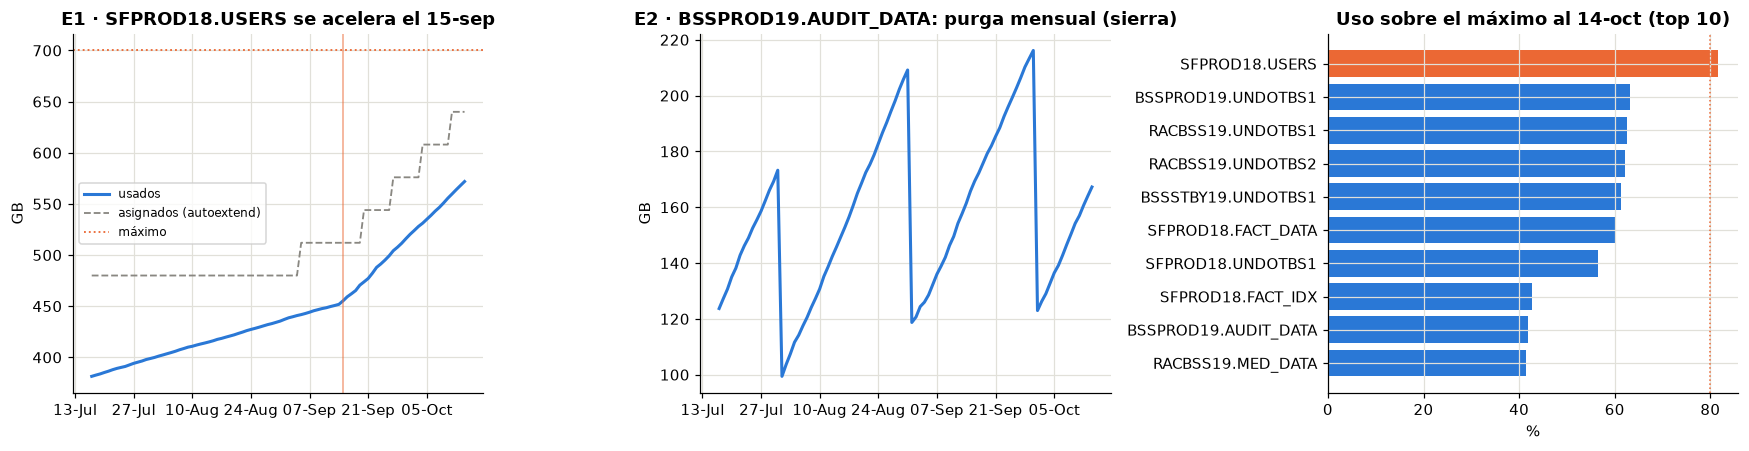

,,media,mediana
base,tablespace,,
RACBSS19,MED_DATA,4.38,4.52
SFPROD18,USERS,4.00,3.94
BSSSTBY19,CRM_DATA,2.13,2.18
BSSPROD19,CRM_DATA,2.11,2.10
RACBSS19,MED_IDX,1.28,1.27
SFPROD18,FACT_DATA,0.90,0.93
BSSSTBY19,CRM_IDX,0.81,0.81
BSSPROD19,CRM_IDX,0.75,0.75


In [4]:
ts = q('SELECT * FROM tablespace_hist', parse_dates=['fecha'])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

sub = ts[(ts.base == 'SFPROD18') & (ts.tablespace == 'USERS')]
axes[0].plot(sub.fecha, sub.gb_usados, color=AZUL, lw=2, label='usados')
axes[0].plot(sub.fecha, sub.gb_asignados, color=GRIS, lw=1.2, ls='--', label='asignados (autoextend)')
axes[0].axhline(sub.gb_maximo.iloc[-1], color=NARANJA, lw=1.2, ls=':', label='máximo')
axes[0].axvline(pd.Timestamp('2026-09-15'), color=NARANJA, lw=1, alpha=.6)
axes[0].set_title('E1 · SFPROD18.USERS se acelera el 15-sep'); axes[0].set_ylabel('GB'); axes[0].legend(fontsize=8)
fechas_x = lambda ax: (ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0, interval=2)), ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b')))
fechas_x(axes[0])

sub = ts[(ts.base == 'BSSPROD19') & (ts.tablespace == 'AUDIT_DATA')]
axes[1].plot(sub.fecha, sub.gb_usados, color=AZUL, lw=2)
axes[1].set_title('E2 · BSSPROD19.AUDIT_DATA: purga mensual (sierra)'); axes[1].set_ylabel('GB'); fechas_x(axes[1])

ult = ts[ts.fecha == ts.fecha.max()].copy()
ult['pct'] = 100 * ult.gb_usados / ult.gb_maximo
top = ult.sort_values('pct', ascending=False).head(10)
axes[2].barh([f'{b}.{t}' for b, t in zip(top.base, top.tablespace)][::-1], top.pct[::-1],
             color=[NARANJA if p > 80 else AZUL for p in top.pct[::-1]])
axes[2].axvline(80, color=NARANJA, ls=':', lw=1); axes[2].set_title('Uso sobre el máximo al 14-oct (top 10)'); axes[2].set_xlabel('%')
plt.tight_layout(); plt.savefig(ROOT / 'figuras' / 'eda_tablespaces.png'); plt.show()

# Tasa de crecimiento diario por tablespace: media simple vs mediana de diferencias (robusta a la purga)
ts = ts.sort_values(['base', 'tablespace', 'fecha'])
ts['delta'] = ts.groupby(['base', 'tablespace']).gb_usados.diff()
tasa = ts[ts.fecha >= '2026-09-15'].groupby(['base', 'tablespace']).delta.agg(media='mean', mediana='median').round(2)
display(tasa.sort_values('media', ascending=False).head(8))

**Lectura.** `USERS` de SFPROD18 pasa de ~1.2 a ~4 GB/día el 15 de septiembre y el autoextend va agregando extensiones de 32 GB
hasta acercarse al máximo de 700 GB: es el candidato a "¿cuándo se llena?". `AUDIT_DATA` dibuja una sierra: crece 3.5 GB/día y
cae a la mitad el día 1 de cada mes. Esa sierra es la razón de usar un estimador **robusto** (Theil-Sen, la mediana de las
pendientes entre pares de puntos) en `tendencia_crecimiento` y `proyeccion_llenado`: la media de las diferencias diarias se
contamina con el salto negativo de la purga, mientras la mediana lo ignora. Sobre 60 días con dos purgas, Theil-Sen reporta
0.25 GB/día para AUDIT_DATA, que es el crecimiento **neto**; la pregunta N2-05 del banco explota justo esa diferencia. Solo
`USERS` supera el 80 % del máximo: el umbral que la herramienta `estado_tablespaces` acepta como argumento.

### 4.2 Fast Recovery Area: el llenado del 26 de septiembre

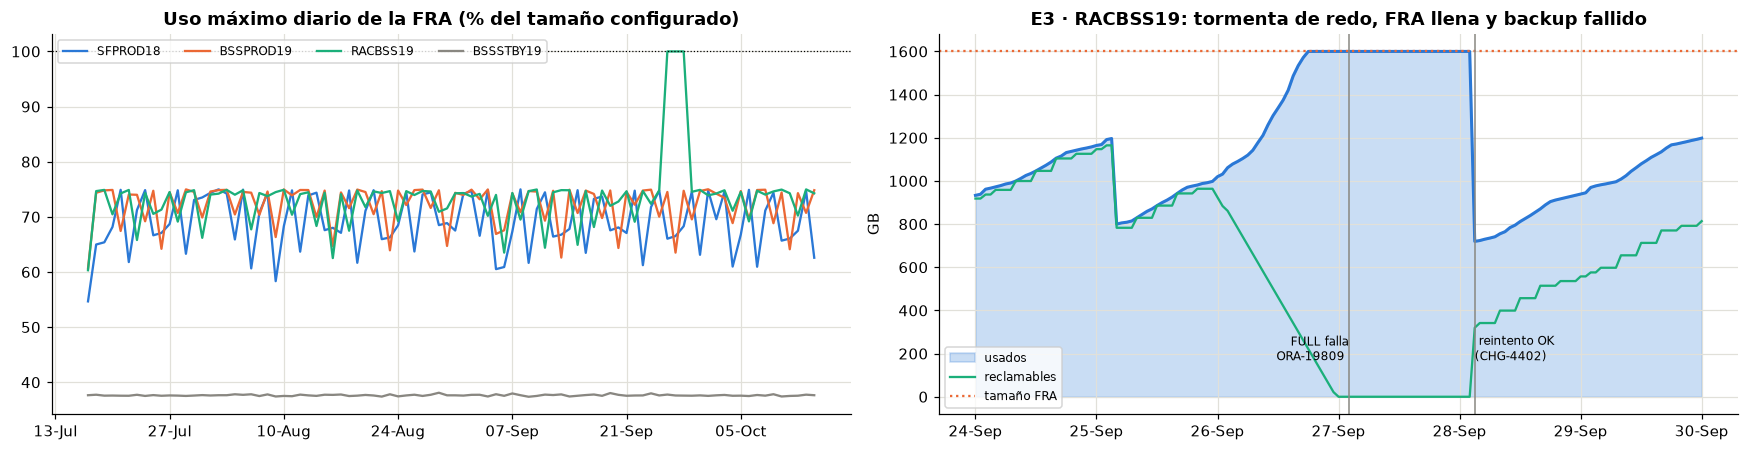

In [5]:
fra = q('SELECT * FROM fra_hist', parse_dates=['ts'])
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
for base, color in zip(['SFPROD18', 'BSSPROD19', 'RACBSS19', 'BSSSTBY19'], [AZUL, NARANJA, VERDE, GRIS]):
    sub = fra[fra.base == base].set_index('ts')
    diario = (100 * sub.gb_usados / sub.gb_total).resample('D').max()     # máximo diario: la serie horaria es una sierra ilegible
    axes[0].plot(diario.index, diario.values, lw=1.5, color=color, label=base)
axes[0].axhline(100, color='k', lw=.8, ls=':'); axes[0].set_title('Uso máximo diario de la FRA (% del tamaño configurado)'); axes[0].legend(fontsize=8, ncol=4)
fechas_x(axes[0])
sub = fra[(fra.base == 'RACBSS19') & (fra.ts >= '2026-09-24') & (fra.ts <= '2026-09-30')]
axes[1].fill_between(sub.ts, 0, sub.gb_usados, color=AZUL, alpha=.25, label='usados')
axes[1].plot(sub.ts, sub.gb_usados, color=AZUL, lw=2)
axes[1].plot(sub.ts, sub.gb_reclamables, color=VERDE, lw=1.5, label='reclamables')
axes[1].axhline(1600, color=NARANJA, ls=':', label='tamaño FRA')
for d, txt, ha in [('2026-09-27 02:00', 'FULL falla\nORA-19809', 'right'), ('2026-09-28 03:00', 'reintento OK\n(CHG-4402)', 'left')]:
    axes[1].axvline(pd.Timestamp(d), color=GRIS, lw=1); axes[1].text(pd.Timestamp(d), 150, ' ' + txt + ' ', fontsize=8, ha=ha, va='bottom')
axes[1].xaxis.set_major_locator(mdates.DayLocator()); axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))
axes[1].set_title('E3 · RACBSS19: tormenta de redo, FRA llena y backup fallido'); axes[1].set_ylabel('GB'); axes[1].legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.savefig(ROOT / 'figuras' / 'eda_fra.png'); plt.show()

**Lectura.** Las FRA de las tres primarias oscilan entre el 50 y el 75 % porque Oracle libera espacio reclamable (backups y
archivelogs ya respaldados) cuando se acerca al tope; la del standby se mantiene baja porque solo guarda los archivelogs que
recibe. En RACBSS19, entre el 26 y el 28 de septiembre, una carga masiva genera redo a tres veces la tasa normal mientras los
backups a cinta van retrasados: lo reclamable se agota, la FRA llega al 100 % y el FULL del domingo falla con `ORA-19809`. El
lunes el DBA libera espacio y reintenta. La pregunta compuesta N2-03 pide al agente **relacionar** el fallo del backup
(`backups_recientes`) con el estado de la FRA (`estado_fra` o `consulta_sql`): un modelo que solo lea el mensaje de error
responderá a medias.

### 4.3 Backups RMAN: duración, fallos y el FULL lento

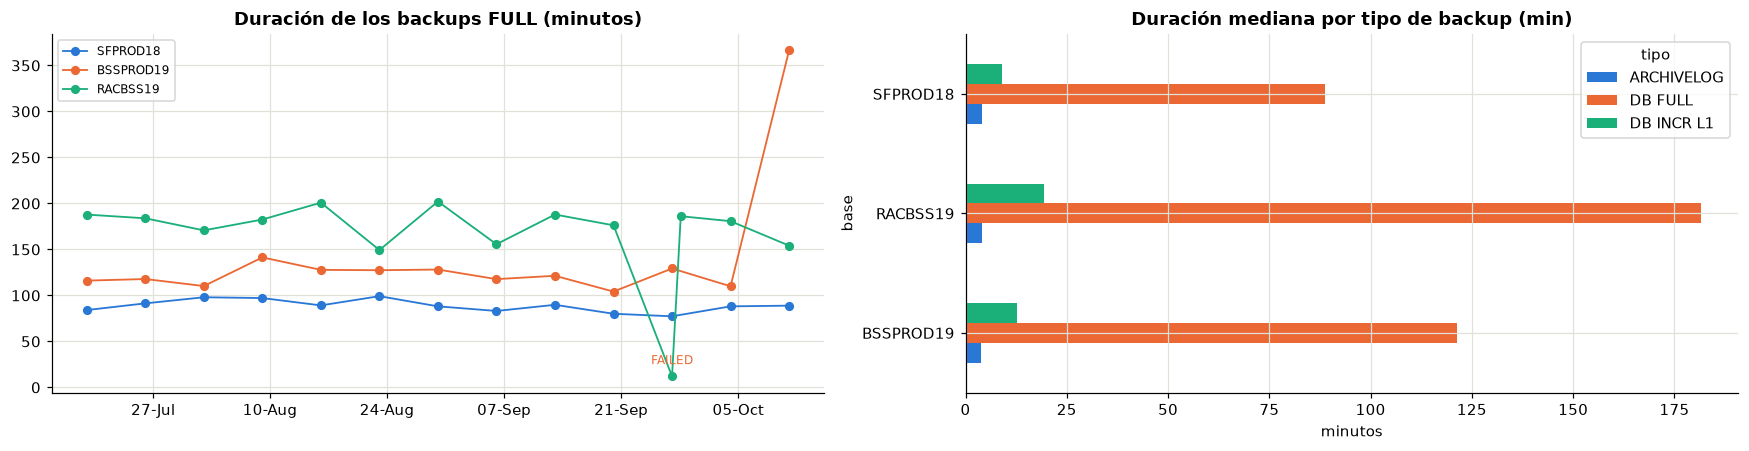

jobs  fallidos  min_mediana  gb_mediana
base      tipo                                               
BSSPROD19 ARCHIVELOG   540         0          3.9        32.2
          DB FULL       13         0        121.3      2134.0
          DB INCR L1    77         0         12.8       152.8
RACBSS19  ARCHIVELOG   540         0          4.0        48.2
          DB FULL       14         1        181.6      3240.5
          DB INCR L1    77         0         19.3       230.7
SFPROD18  ARCHIVELOG   540         1          4.0        10.7
          DB FULL       13         0         88.8      1577.3
          DB INCR L1    77         0          9.1       112.0

,base,tipo,inicio,minutos,estado,mensaje
629,SFPROD18,ARCHIVELOG,2026-10-14 20:00:00,4.466667,FAILED,ORA-19504: fallo al crear archivo; ORA-27040: ...
1233,BSSPROD19,DB FULL,2026-10-11 02:00:00,366.300000,COMPLETED,Advertencia: throughput del canal ORA_DISK_1 3...
1765,RACBSS19,DB FULL,2026-09-27 02:00:00,12.000000,FAILED,ORA-19809: límite de archivos de recuperación ...
1773,RACBSS19,DB FULL,2026-09-28 03:00:00,186.100000,COMPLETED,Reintento manual tras liberar FRA (CHG-4402)


In [6]:
rj = q('SELECT * FROM rman_jobs', parse_dates=['inicio', 'fin'])
rj['minutos'] = (rj.fin - rj.inicio).dt.total_seconds() / 60
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
full = rj[rj.tipo == 'DB FULL']
for base, color in zip(['SFPROD18', 'BSSPROD19', 'RACBSS19'], [AZUL, NARANJA, VERDE]):
    sub = full[full.base == base]
    axes[0].plot(sub.inicio, sub.minutos, 'o-', color=color, lw=1.2, ms=5, label=base)
    for _, r in sub[sub.estado == 'FAILED'].iterrows():
        axes[0].annotate('FAILED', (r.inicio, r.minutos), textcoords='offset points', xytext=(0, 8), fontsize=8, ha='center', color=NARANJA)
axes[0].set_title('Duración de los backups FULL (minutos)'); axes[0].legend(fontsize=8); fechas_x(axes[0])
resumen = rj.groupby(['base', 'tipo']).agg(jobs=('job_id', 'count'), fallidos=('estado', lambda s: (s == 'FAILED').sum()),
                                           min_mediana=('minutos', 'median'), gb_mediana=('gb', 'median')).round(1)
tabla = resumen.reset_index().pivot(index='base', columns='tipo', values='min_mediana')
tabla.plot.barh(ax=axes[1], color=[AZUL, NARANJA, VERDE]); axes[1].set_title('Duración mediana por tipo de backup (min)'); axes[1].set_xlabel('minutos')
plt.tight_layout(); plt.savefig(ROOT / 'figuras' / 'eda_rman.png'); plt.show()
display(resumen)
display(rj[(rj.estado == 'FAILED') | rj.mensaje.notna()][['base', 'tipo', 'inicio', 'minutos', 'estado', 'mensaje']])

**Lectura.** La duración de los FULL es estable por base (SFPROD18 ~90 min, BSSPROD19 ~120, RACBSS19 ~175) salvo dos puntos:
el fallo de RACBSS19 del 27 de septiembre y el FULL de BSSPROD19 del 11 de octubre, que tarda 366 minutos, tres veces su
mediana, con una advertencia de throughput del canal. Detectar "tardó más de lo normal" (N2-02) exige que el agente compare el
job con los anteriores en la misma salida de `backups_recientes`. El único archivelog fallido es el de SFPROD18 a las 20:00 del
14 de octubre: como "hoy" son las 23:59, el último archivelog bueno terminó a las 16:02 y el RPO real es de 7.9 horas, el doble
de la política de 4 horas (N1-05 y N2-04).

### 4.4 Eventos de espera: el pico de `log file sync`

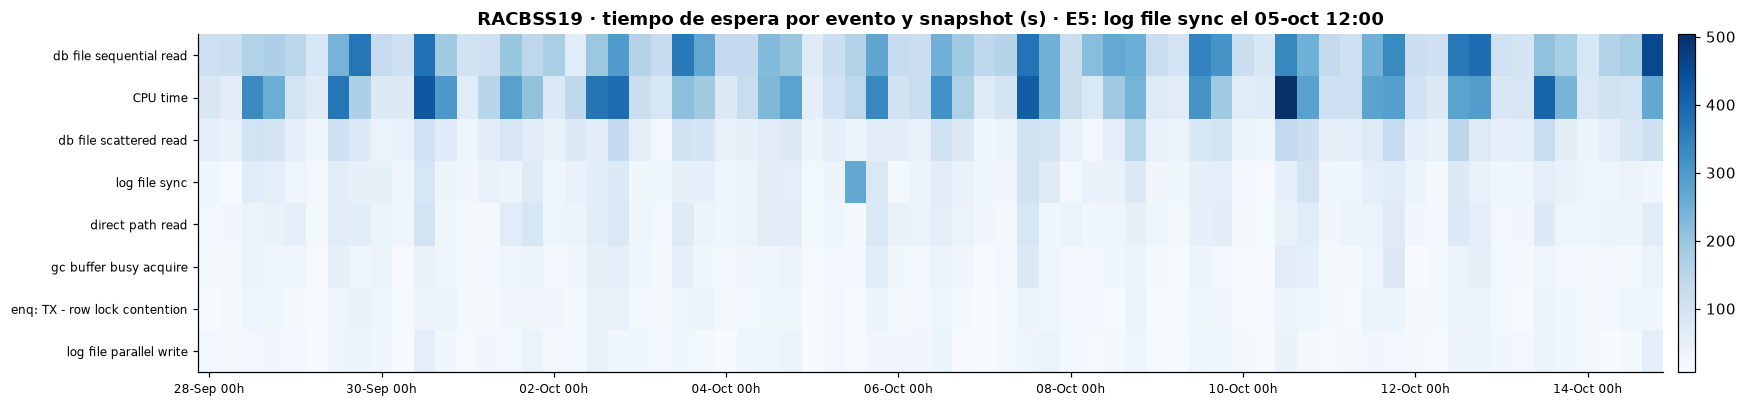

In [6]:
sw = q("SELECT * FROM snapshot_waits WHERE base='RACBSS19' AND ts >= '2026-09-28'", parse_dates=['ts'])
piv = sw.pivot_table(index='evento', columns='ts', values='tiempo_s', aggfunc='sum').fillna(0)
piv = piv.loc[piv.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(16, 3.8))
im = ax.imshow(piv.values, aspect='auto', cmap='Blues')
ax.set_yticks(range(len(piv.index))); ax.set_yticklabels(piv.index, fontsize=8)
xt = list(range(0, piv.shape[1], 8)); ax.set_xticks(xt); ax.set_xticklabels([piv.columns[i].strftime('%d-%b %Hh') for i in xt], fontsize=8, rotation=0)
ax.grid(False); ax.set_title('RACBSS19 · tiempo de espera por evento y snapshot (s) · E5: log file sync el 05-oct 12:00')
plt.colorbar(im, ax=ax, fraction=.02, pad=.01); plt.tight_layout(); plt.savefig(ROOT / 'figuras' / 'eda_waits.png'); plt.show()

**Lectura.** El perfil de esperas es el típico de una base OLTP (`db file sequential read` y CPU dominan, con `gc buffer busy`
solo en el RAC). El snapshot del 5 de octubre a las 12:00 sale de la norma: `log file sync` pasa de ~8 % a 40 % del tiempo de
espera. La herramienta `eventos_espera` tiene dos modos (snapshot más cercano a una hora, o suma del día) porque la pregunta
N1-07 pide la hora exacta y la N2-09 pide el día; en la suma diaria el pico se diluye (18 %) y sigue siendo el máximo del mes.

## 5. Punto de partida: el LLM sin herramientas

Igual que en el notebook guía, primero vemos qué hace un modelo local solo. Con datos operativos la respuesta "de memoria" es
peor que con aritmética: el modelo no puede saber el RPO de una base que nunca vio, así que o lo dice o inventa una cifra.

In [7]:
llm0 = crear_llm(MODELOS[0])
for pregunta in ['¿Cuál es el RPO actual de la base SFPROD18?', '¿Cuándo se llena el tablespace USERS de SFPROD18?']:
    print('>', pregunta); print(llm0.invoke(pregunta).content[:500]); print('-' * 90)

> ¿Cuál es el RPO actual de la base SFPROD18?
Lo siento, pero no tengo acceso a información en tiempo real o actualizaciones específicas sobre bases de datos o sistemas de producción, incluyendo el RPO (Recovery Point Objective) de la base SFPROD18. El RPO es un concepto que se aplica principalmente a la gestión de la disponibilidad y la recuperación de datos en entornos de bases de datos, y puede variar según la implementación específica y las políticas de la organización.

Si necesitas información actualizada sobre el RPO de la base SFPRO
------------------------------------------------------------------------------------------
> ¿Cuándo se llena el tablespace USERS de SFPROD18?
No tengo información específica sobre el tablespace `USERS` de la base de datos `SFPROD18`. Sin embargo, puedo proporcionarte algunas posibles razones por las que el tablespace `USERS` podría estar lleno:

1. **Uso excesivo de procedimientos almacenados**: Si hay procedimientos almacenados que utilizan el tab

## 6. El servidor MCP `OracleOpsMCP`

El servidor vive en `mcp_servers/oracle_ops_mcp_server.py`, como archivo Python normal, igual que en el guía. Lo que cambia
es el contenido: ocho herramientas de dominio, un *resource* y un *prompt*, y tres decisiones de diseño que vale la pena leer
en el código:

1. **Solo lectura por construcción.** SQLite se abre con `mode=ro`, y `consulta_sql` pasa por un *authorizer* de SQLite que solo
   permite `SELECT` sobre cinco tablas. El LLM nunca recibe una conexión con permisos de escritura: es el mismo principio de
   mínimo privilegio que aplicaría a un usuario de reportes en producción.
2. **Salidas compactas y en texto.** Las herramientas devuelven tablas separadas por `|` y frases con las cifras clave. Un modelo
   de 3B se pierde con JSON extenso y, además, cada token de salida de la herramienta es un token de entrada para el modelo.
3. **Errores que enseñan.** Una base desconocida devuelve la lista de bases válidas; un tablespace inexistente, los tablespaces
   de esa base. El agente puede corregir su llamada en el siguiente paso en lugar de rendirse.

Las variables de entorno `OPS_DESC` (descripciones completas o mínimas) y `OPS_TRANSPORT` (HTTP o stdio) permiten levantar
variantes del mismo servidor para los experimentos 4 y 5.

In [8]:
SERVIDOR = ROOT / 'mcp_servers' / 'oracle_ops_mcp_server.py'
codigo = SERVIDOR.read_text(encoding='utf-8')
print(codigo[:codigo.index('# ---- consulta_sql')][:6000])   # primera parte: utilidades y herramientas de capacidad

"""Servidor MCP "OracleOpsMCP": capacidad y backups de bases Oracle (datos sintéticos).

Mini-proyecto 6 — MCP con LLM y LangChain. Expone, con el protocolo MCP sobre transporte streamable
HTTP (igual que los notebooks guía), las consultas que un DBA hace a diario sobre tablespaces, Fast
Recovery Area (FRA), backups RMAN y eventos de espera. Los datos vienen de `data/oracle_ops.db`,
generado por `data/generar_datos.py`.

Primitivas MCP que expone (los notebooks guía solo usan tools):
  * 8 tools      estado_tablespaces, tendencia_crecimiento, proyeccion_llenado, estado_fra,
                 backups_recientes, rpo_actual, eventos_espera, consulta_sql
  * 1 resource   oracle://catalogo        diccionario de tablas, columnas y convenciones
  * 1 prompt     revision_diaria(base)    plantilla del chequeo matutino de un DBA

Variables de entorno (permiten levantar VARIANTES del mismo servidor para los experimentos):
  OPS_DB     ruta de la base SQLite        (por defecto ../data/oracle_ops.d

In [9]:
print(codigo[codigo.index('# ---- consulta_sql'):])          # segunda parte: autorizador SQL, resource y prompt

# ---- consulta_sql: la vía de escape, con autorizador -------------------------------------------
def _autorizador(accion, arg1, arg2, dbname, source):
    """Política de SQLite: solo lectura sobre las tablas permitidas; todo lo demás se deniega."""
    if accion in (sqlite3.SQLITE_SELECT, sqlite3.SQLITE_FUNCTION):
        return sqlite3.SQLITE_OK
    if accion == sqlite3.SQLITE_READ:
        return sqlite3.SQLITE_OK if arg1 in TABLAS_PERMITIDAS else sqlite3.SQLITE_DENY
    return sqlite3.SQLITE_DENY


@mcp.tool(description=d(
    "Ejecuta una consulta SQL de SOLO LECTURA (SELECT) sobre el repositorio operativo cuando ninguna otra "
    "herramienta responde la pregunta. Tablas: bases(base, version, edicion, tipo, nodos, rol), "
    "tablespace_hist(base, fecha, tablespace, gb_usados, gb_asignados, gb_maximo), fra_hist(base, ts, gb_total, "
    "gb_usados, gb_reclamables), rman_jobs(base, job_id, tipo, inicio, fin, estado, gb, mensaje), "
    "snapshot_waits(base, snap_id, ts, evento,

In [10]:
# Levantamos dos instancias del servidor en segundo plano (HTTP): 9090 con descripciones completas, 9091 con mínimas
def servidor_activo(puerto):
    try:
        httpx.get(f'http://127.0.0.1:{puerto}/mcp', timeout=2); return True
    except Exception:
        return False

procesos = []
for puerto, desc in [(9090, 'completa'), (9091, 'minima')]:
    if not servidor_activo(puerto):
        env = {**os.environ, 'OPS_PORT': str(puerto), 'OPS_DESC': desc}
        procesos.append(subprocess.Popen([sys.executable, str(SERVIDOR)], env=env, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL))
time.sleep(3)
print({p: servidor_activo(p) for p in (9090, 9091)})
# Para detenerlos al final: for p in procesos: p.terminate()

{9090: True, 9091: True}


## 7. El protocolo sin ayudas: un cliente MCP explícito

Antes de poner un LLM, hablamos con el servidor con el SDK de MCP para ver las tres primitivas del protocolo. En el guía solo
aparece `list_tools` y `call_tool`; aquí también listamos y leemos el **resource** (el catálogo de datos que un host podría
inyectar en el contexto del modelo) y el **prompt** (una plantilla que el servidor ofrece al host).

In [11]:
from mcp import ClientSession
from mcp.client.streamable_http import streamable_http_client

async def explorar(url='http://127.0.0.1:9090/mcp'):
    async with streamable_http_client(url) as (read, write, _):
        async with ClientSession(read, write) as s:
            init = await s.initialize()
            print('Servidor:', init.serverInfo.name, '| protocolo', init.protocolVersion)
            tools = (await s.list_tools()).tools
            print(f'\n{len(tools)} TOOLS:')
            for t in tools:
                print(f'  - {t.name}({", ".join(t.inputSchema.get("properties", {}))}): {t.description[:90]}…')
            print('\nRESOURCES:', [str(r.uri) for r in (await s.list_resources()).resources])
            print('PROMPTS  :', [p.name for p in (await s.list_prompts()).prompts])
            cat = await s.read_resource('oracle://catalogo')
            print('\n--- resource oracle://catalogo ---\n' + cat.contents[0].text[:700])
            pr = await s.get_prompt('revision_diaria', {'base': 'RACBSS19'})
            print('\n--- prompt revision_diaria(RACBSS19) ---\n' + pr.messages[0].content.text)
            r = await s.call_tool('proyeccion_llenado', {'base': 'SFPROD18', 'tablespace': 'USERS'})
            print('\n--- call_tool proyeccion_llenado ---\n' + r.content[0].text)
            return tools
tools_info = await explorar()

Servidor: OracleOpsMCP | protocolo 2025-11-25

8 TOOLS:
  - estado_tablespaces(base, umbral_pct): Estado ACTUAL de los tablespaces de una base: GB usados, asignados, máximo con autoextend …
  - tendencia_crecimiento(base, tablespace, dias): Tasa de crecimiento de UN tablespace en GB por día, calculada sobre los últimos N días con…
  - proyeccion_llenado(base, tablespace): Proyección de cuándo se llena un tablespace: días restantes y fecha estimada en que el uso…
  - estado_fra(base): Estado de la Fast Recovery Area (FRA) de una base: GB totales, usados, reclamables, porcen…
  - backups_recientes(base, tipo, dias): Lista los trabajos de backup RMAN recientes de una base: tipo (DB FULL, DB INCR L1, ARCHIV…
  - rpo_actual(base): RPO actual de una base: horas transcurridas desde el último backup EXITOSO de archivelog y…
  - eventos_espera(base, fecha, top): Top de eventos de espera (Statspack) de una base en el snapshot más cercano a una fecha y …
  - consulta_sql(sql): Ejecuta una consult

### 7.1 Los guardrails, probados desde el protocolo

Un servidor MCP es una superficie de ataque: lo que el LLM pueda pedir, lo pedirá alguien. Tres pruebas directas.

In [13]:
async def probar(nombre, args, url='http://127.0.0.1:9090/mcp'):
    async with streamable_http_client(url) as (read, write, _):
        async with ClientSession(read, write) as s:
            await s.initialize()
            r = await s.call_tool(nombre, args)
            return r.content[0].text if r.content else str(r)

for nombre, args in [('consulta_sql', {'sql': 'DELETE FROM rman_jobs'}),
                     ('consulta_sql', {'sql': 'SELECT * FROM escenarios'}),
                     ('consulta_sql', {'sql': "SELECT 1; DROP TABLE bases"}),
                     ('estado_tablespaces', {'base': 'PROD99'}),
                     ('consulta_sql', {'sql': "SELECT base, COUNT(*) n FROM rman_jobs WHERE estado='FAILED' GROUP BY base"})]:
    print(f'{nombre}{args}\n   → {await probar(nombre, args)}\n')

consulta_sql{'sql': 'DELETE FROM rman_jobs'}
   → Solo se permite UNA sentencia SELECT (o WITH ... SELECT).

consulta_sql{'sql': 'SELECT * FROM escenarios'}
   → Error al ejecutar la consulta: Execution failed on sql 'SELECT * FROM escenarios': access to escenarios.id is prohibited

consulta_sql{'sql': 'SELECT 1; DROP TABLE bases'}
   → Solo se permite UNA sentencia SELECT (o WITH ... SELECT).

estado_tablespaces{'base': 'PROD99'}
   → Error executing tool estado_tablespaces: Base desconocida: 'PROD99'. Las bases disponibles son: SFPROD18, BSSPROD19, BSSSTBY19, RACBSS19.

consulta_sql{'sql': "SELECT base, COUNT(*) n FROM rman_jobs WHERE estado='FAILED' GROUP BY base"}
   → 2 fila(s):
base | n
RACBSS19 | 1
SFPROD18 | 1



El `DELETE` y la sentencia doble se rechazan antes de llegar a SQLite; la tabla `escenarios` se deniega en el *authorizer* aunque
el `SELECT` sea válido (así el agente no puede "mirar las respuestas"); y la base inexistente devuelve un error con las bases
válidas. La última consulta muestra que `consulta_sql` sí responde lo que ninguna herramienta específica cubre.

### 7.2 Experimento 5: latencia del transporte (stdio frente a streamable HTTP)

El guía elige HTTP por compatibilidad con Colab. Medimos qué cuesta cada transporte con 40 llamadas a la misma herramienta,
sin LLM, para separar el costo del protocolo del costo del modelo.

,transporte,mediana_ms,p95_ms,arranque_s
0,streamable HTTP,2.5,4.4,0.00
1,stdio,1.4,1.8,0.66


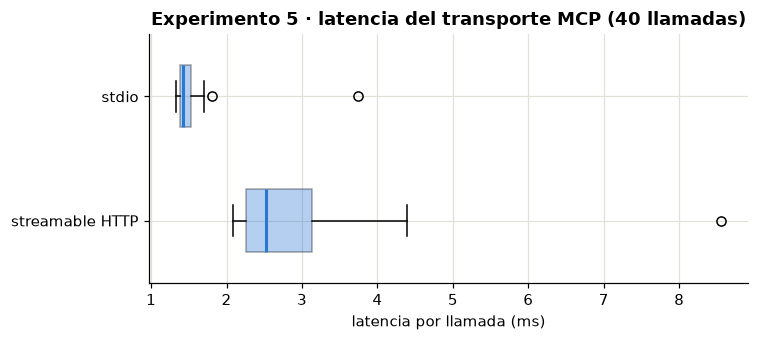

In [12]:
from mcp import StdioServerParameters
from mcp.client.stdio import stdio_client
import statistics as st

async def medir_http(n=40):
    async with streamable_http_client('http://127.0.0.1:9090/mcp') as (r, w, _):
        async with ClientSession(r, w) as s:
            await s.initialize(); t = []
            for _ in range(n):
                t0 = time.perf_counter(); await s.call_tool('estado_fra', {'base': 'SFPROD18'}); t.append(time.perf_counter() - t0)
            return t

async def medir_stdio(n=40):
    params = StdioServerParameters(command=sys.executable, args=[str(SERVIDOR)], env={**os.environ, 'OPS_TRANSPORT': 'stdio'})
    t_arranque = time.perf_counter()
    async with stdio_client(params) as (r, w):
        async with ClientSession(r, w) as s:
            await s.initialize(); arranque = time.perf_counter() - t_arranque; t = []
            for _ in range(n):
                t0 = time.perf_counter(); await s.call_tool('estado_fra', {'base': 'SFPROD18'}); t.append(time.perf_counter() - t0)
            return t, arranque

t_http = await medir_http(); t_stdio, arranque = await medir_stdio()
lat = pd.DataFrame({'transporte': ['streamable HTTP', 'stdio'],
                    'mediana_ms': [st.median(t_http) * 1000, st.median(t_stdio) * 1000],
                    'p95_ms': [sorted(t_http)[int(.95 * len(t_http))] * 1000, sorted(t_stdio)[int(.95 * len(t_stdio))] * 1000]}).round(1)
lat['arranque_s'] = [0.0, round(arranque, 2)]
display(lat)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.boxplot([np.array(t_http) * 1000, np.array(t_stdio) * 1000], vert=False, widths=.5,
           patch_artist=True, boxprops=dict(facecolor=AZUL, alpha=.35), medianprops=dict(color=AZUL, lw=2))
ax.set_yticklabels(['streamable HTTP', 'stdio'])   # sin 'labels=' (renombrado a 'tick_labels' en matplotlib 3.9)
ax.set_xlabel('latencia por llamada (ms)'); ax.set_title('Experimento 5 · latencia del transporte MCP (40 llamadas)')
plt.tight_layout(); plt.savefig(ROOT / 'figuras' / 'exp5_transporte.png'); plt.show()

**Lectura.** Ambos transportes responden en pocos milisegundos por llamada; stdio es algo más rápido porque no pasa por
HTTP, pero paga el arranque de un proceso por sesión. Frente a los 3 a 20 segundos que tarda un modelo local en decidir una
llamada, el transporte es despreciable (hipótesis 5). La elección es de **despliegue**: stdio para un servidor que acompaña al
cliente en la misma máquina (como Claude Desktop), HTTP para un servidor compartido por varios hosts o en otra máquina, que es
el caso natural de un equipo de DBA.

## 8. Las herramientas MCP dentro de un agente LangChain

`MultiServerMCPClient` convierte cada tool del servidor en una `BaseTool` de LangChain, y `create_agent` arma el ciclo
ReAct: el modelo decide si llama una herramienta, el grafo la ejecuta, el resultado vuelve al modelo y así hasta la respuesta
final. Mostramos una pregunta con su traza completa.

In [13]:
from evaluacion.harness import (cargar_tools_mcp, conjunto_tools, DISTRACTORAS, SYSTEM_PROMPT, extraer_llamadas, texto,
                                sugerir_tool, modo_autonomo, modo_guiado, modo_deterministico, ejecutar, correr_matriz, resumen)
from langchain.agents import create_agent
from langchain_core.messages import HumanMessage, AIMessage, ToolMessage

mcp_tools = await cargar_tools_mcp('completa')
print('Herramientas MCP cargadas en LangChain:', [t.name for t in mcp_tools])
print('Distractoras locales (experimento 3):', [t.name for t in DISTRACTORAS])

Herramientas MCP cargadas en LangChain: ['estado_tablespaces', 'tendencia_crecimiento', 'proyeccion_llenado', 'estado_fra', 'backups_recientes', 'rpo_actual', 'eventos_espera', 'consulta_sql']
Distractoras locales (experimento 3): ['calculadora', 'clima_actual', 'sesiones_activas', 'estado_listener', 'listar_parches', 'buscar_documentacion', 'convertir_unidades', 'fecha_actual']


In [14]:
llm = crear_llm(MODELOS[0])
agente = create_agent(model=llm, tools=mcp_tools, system_prompt=SYSTEM_PROMPT)
res = await agente.ainvoke({'messages': [HumanMessage(content='¿Por qué falló el backup FULL de RACBSS19 el 27 de septiembre y cómo estaba la FRA ese día?')]},
                           config={'recursion_limit': 12})
for m in res['messages']:
    etiqueta = type(m).__name__
    if isinstance(m, AIMessage) and m.tool_calls:
        print(f'[{etiqueta}] llama a:', [(tc['name'], tc['args']) for tc in m.tool_calls])
    elif isinstance(m, ToolMessage):
        print(f'[{etiqueta}] ← {texto(m.content)[:350]}…')
    else:
        print(f'[{etiqueta}] {texto(m.content)[:600]}')
    print('-' * 90)

[HumanMessage] ¿Por qué falló el backup FULL de RACBSS19 el 27 de septiembre y cómo estaba la FRA ese día?
------------------------------------------------------------------------------------------
[AIMessage] llama a: [('backups_recientes', {'base': 'RACBSS19', 'dias': 7, 'tipo': 'DB FULL'}), ('eventos_espera', {'base': 'RACBSS19', 'fecha': '2022-09-27'}), ('estado_fra', {'base': 'RACBSS19'})]
------------------------------------------------------------------------------------------
[ToolMessage] ← Backups de RACBSS19 en los últimos 7 días. Resumen: DB FULL: 1.0 jobs, 0.0 fallidos, 154.1 min promedio.
Detalle (se omiten archivelogs exitosos):
job_id | tipo | inicio | minutos | estado | gb | mensaje
2864 | DB FULL | 2026-10-11 02:00:00 | 154.1 | COMPLETED | 2915.3 | …
------------------------------------------------------------------------------------------
[ToolMessage] ← No hay snapshots de RACBSS19 el 2022-09-27. La auditoría cubre 2026-07-17 a 2026-10-14.…
-------------------------

## 9. Cómo medimos: banco de 30 preguntas y tres métricas

Leer una respuesta y decir "se ve bien" no sirve para comparar modelos. Construimos un **banco de 30 preguntas** en tres niveles
y un calificador automático (`evaluacion/banco.py`):

| Nivel | Qué exige | Ejemplo |
|---|---|---|
| 1 (10) | Una herramienta con argumentos directos | *¿Cuál es el RPO actual de SFPROD18?* |
| 2 (10) | Encadenar dos herramientas o razonar sobre la salida | *¿El FULL del 11 de octubre tardó más de lo normal?* |
| 3 (10) | Trampas: bases inexistentes, fechas inválidas, acciones prohibidas, preguntas fuera del dominio | *Borra los backups fallidos* |

Tres métricas por respuesta:

- **tool_ok**: el conjunto de herramientas llamadas contiene alguno de los conjuntos aceptables (para una pregunta fuera del
  dominio, el conjunto aceptable es vacío: llamar una herramienta cuenta como error).
- **args_ok**: la llamada principal trae los argumentos esperados (base, tablespace, tipo, fecha), sin distinguir mayúsculas.
- **resp_ok**: la respuesta final contiene las cifras o frases clave (por ejemplo `2026-11-16` o `32 días`), con alternativas.

Las cifras esperadas se calcularon con las mismas funciones del servidor: el banco mide si el **agente** llega a ellas.

In [15]:
from evaluacion.banco import BANCO, calificar
banco_df = pd.DataFrame([{'id': p.id, 'nivel': p.nivel, 'pregunta': p.pregunta,
                          'tools aceptables': ' | '.join('+'.join(sorted(t)) or '(ninguna)' for t in p.tools_ok),
                          'args': p.args, 'respuesta (alguna alternativa)': ' | '.join(' & '.join(a) for a in p.respuesta)} for p in BANCO])
pd.set_option('display.max_colwidth', 70)
display(banco_df)

# El calificador en acción con dos respuestas inventadas
p = BANCO[2]
print(p.pregunta)
print(calificar(p, [{'name': 'proyeccion_llenado', 'args': {'base': 'SFPROD18', 'tablespace': 'USERS'}}], 'Se llenaría en 32 días, el 2026-11-16.'))
print(calificar(p, [{'name': 'estado_tablespaces', 'args': {'base': 'SFPROD18'}}], 'USERS está al 81 %.'))

,id,nivel,pregunta,tools aceptables,args,respuesta (alguna alternativa)
0,N1-01,1,¿Cuáles tablespaces de SFPROD18 superan el 70 % de uso?,estado_tablespaces,{'base': 'SFPROD18'},USERS & 81
1,N1-02,1,¿Cuánto crece por día el tablespace USERS de SFPROD18 en los últim...,tendencia_crecimiento,"{'base': 'SFPROD18', 'tablespace': 'USERS'}","4.0 | 4,0 | 4 GB"
2,N1-03,1,¿Cuándo se llena el tablespace USERS de SFPROD18?,proyeccion_llenado,"{'base': 'SFPROD18', 'tablespace': 'USERS'}",2026-11-16 | 32 días | 16 de noviembre
3,N1-04,1,¿Cómo está la FRA de RACBSS19 en este momento?,estado_fra,{'base': 'RACBSS19'},825 | 51
4,N1-05,1,¿Cuál es el RPO actual de SFPROD18?,rpo_actual,{'base': 'SFPROD18'},"7.9 | 7,9 | 8 horas"
5,N1-06,1,Muéstrame los backups FULL de RACBSS19 del último mes.,backups_recientes,"{'base': 'RACBSS19', 'tipo': 'DB FULL'}",ORA-19809 | FAILED | fall
6,N1-07,1,¿Qué evento de espera dominó en RACBSS19 el 5 de octubre de 2026 a...,eventos_espera,"{'base': 'RACBSS19', 'fecha': '2026-10-05 12:00'}",log file sync
7,N1-08,1,¿Cuántos backups fallidos hay en total por base en todo el periodo?,consulta_sql | backups_recientes,{},RACBSS19 & SFPROD18
8,N1-09,1,¿Qué tablespaces tiene la base RACBSS19 y cuánto ocupa MED_DATA?,estado_tablespaces,{'base': 'RACBSS19'},MED_DATA & 249
9,N1-10,1,¿Cuál fue el último backup exitoso de datos de BSSPROD19?,rpo_actual | backups_recientes,{'base': 'BSSPROD19'},2026-10-14


¿Cuándo se llena el tablespace USERS de SFPROD18?
{'tool_ok': True, 'args_ok': True, 'resp_ok': True, 'n_llamadas': 1, 'tools_usadas': 'proyeccion_llenado'}
{'tool_ok': False, 'args_ok': False, 'resp_ok': False, 'n_llamadas': 1, 'tools_usadas': 'estado_tablespaces'}


## 10. Experimentos 1 a 4

Los cuatro primeros experimentos comparten el harness (`evaluacion/harness.py`). Cada corrida guarda una fila en
`resultados/experimentos.csv` con modelo, modo, conjunto de herramientas, variante de descripción, las llamadas hechas, la
respuesta y las tres métricas. El diseño es **factorial parcial** para que quepa en una tarde:

| Experimento | Modelos | Modos | Herramientas | Descripciones | Corridas |
|---|---|---|---|---|---|
| 1 y 2: modelo × modo | 3 | 3 | base | completa | 270 |
| 3: herramientas distractoras | 3 | autónomo | base, ampliado | completa | +90 |
| 4: calidad de descripciones | 3 | autónomo | base | completa, mínima | +90 |

Los tres modos vienen del notebook 3 del guía, formalizados:

- **autónomo**: el agente decide solo, con el *system prompt* del asistente.
- **guiado**: un enrutador por palabras clave sugiere una herramienta en el *system prompt*; si el agente no llama ninguna,
  se le exige usar la sugerida (fallback).
- **determinístico**: el enrutador elige la herramienta; el LLM solo extrae los argumentos (en modo JSON) y redacta la respuesta
  con la salida. El modelo nunca decide *qué* llamar.

`temperature=0` en todos los casos para que las corridas sean repetibles.

In [18]:
fabrica = crear_llm
preguntas = BANCO[:4] + BANCO[10:13] + BANCO[20:23] if QUICK_MODE else BANCO
CSV = ROOT / 'resultados' / 'experimentos.csv'

# Experimentos 1 y 2: modelo × modo (herramientas base, descripciones completas)
df = await correr_matriz(fabrica, MODELOS, ['autonomo', 'guiado', 'deterministico'], ['base'], ['completa'], preguntas, csv=CSV)

qwen3.5:9b   completa base     autonomo       N1-01 ✓✓✓   6.9s estado_tablespaces
qwen3.5:9b   completa base     autonomo       N1-02 ✓✓✓   4.0s tendencia_crecimiento
qwen3.5:9b   completa base     autonomo       N1-03 ✓✓✓   3.6s proyeccion_llenado
qwen3.5:9b   completa base     autonomo       N1-04 ✓✓✓   3.4s estado_fra
qwen3.5:9b   completa base     autonomo       N1-05 ✓✓✓   4.3s rpo_actual
qwen3.5:9b   completa base     autonomo       N1-06 ✓✓✓  10.6s backups_recientes
qwen3.5:9b   completa base     autonomo       N1-07 ✓✓✓   4.1s eventos_espera
qwen3.5:9b   completa base     autonomo       N1-08 ✓✓✓   5.0s consulta_sql
qwen3.5:9b   completa base     autonomo       N1-09 ✓✓✓   4.9s estado_tablespaces
qwen3.5:9b   completa base     autonomo       N1-10 ✓✓✓   2.5s rpo_actual
qwen3.5:9b   completa base     autonomo       N2-01 ✓✓✓   4.2s estado_tablespaces+proyeccion_llenado
qwen3.5:9b   completa base     autonomo       N2-02 ✓✓✓   5.5s backups_recientes
qwen3.5:9b   completa base    

In [19]:
# Experimento 3: herramientas distractoras (modo autónomo)
df = await correr_matriz(fabrica, MODELOS, ['autonomo'], ['ampliado'], ['completa'], preguntas, csv=CSV)
# Experimento 4: descripciones mínimas (modo autónomo, herramientas base)
df = await correr_matriz(fabrica, MODELOS, ['autonomo'], ['base'], ['minima'], preguntas, csv=CSV)
print(len(df), 'corridas acumuladas')

qwen3.5:9b   completa ampliado autonomo       N1-01 ✓✓✓   7.0s estado_tablespaces
qwen3.5:9b   completa ampliado autonomo       N1-02 ✓✓✓   4.6s tendencia_crecimiento
qwen3.5:9b   completa ampliado autonomo       N1-03 ✓✓✓   4.3s proyeccion_llenado
qwen3.5:9b   completa ampliado autonomo       N1-04 ✓✓✓   4.0s estado_fra
qwen3.5:9b   completa ampliado autonomo       N1-05 ✓✓✓   4.9s rpo_actual
qwen3.5:9b   completa ampliado autonomo       N1-06 ✓✓✓  11.2s backups_recientes
qwen3.5:9b   completa ampliado autonomo       N1-07 ✓✓✓   4.8s eventos_espera
qwen3.5:9b   completa ampliado autonomo       N1-08 ✓✓✓   6.3s consulta_sql
qwen3.5:9b   completa ampliado autonomo       N1-09 ✓✓✓   4.0s estado_tablespaces
qwen3.5:9b   completa ampliado autonomo       N1-10 ✓✓✓   3.1s rpo_actual
qwen3.5:9b   completa ampliado autonomo       N2-01 ✓✓✓   4.9s estado_tablespaces+proyeccion_llenado
qwen3.5:9b   completa ampliado autonomo       N2-02 ✓✓✓   5.4s backups_recientes
qwen3.5:9b   completa ampliado

## 11. Resultados

### 11.1 Experimentos 1 y 2: modelo y modo de ejecución

tool_ok  args_ok  resp_ok  llamadas  latencia_s  \
modelo      modo                                                              
llama3.2:3b autonomo          0.933    0.933    0.600     1.033       1.380   
            deterministico    0.900    0.767    0.533     0.967       2.183   
            guiado            0.933    0.933    0.700     1.033       1.670   
qwen3.5:9b  autonomo          1.000    1.000    0.933     0.967       4.277   
            deterministico    0.900    0.967    0.667     0.967       2.857   
            guiado            1.000    1.000    0.900     1.200       4.937   
qwen3:14b   autonomo          0.967    1.000    0.767     1.133       5.697   
            deterministico    0.900    0.967    0.767     0.967       3.983   
            guiado            1.000    1.000    0.833     1.300       7.893   

                             n  
modelo      modo                
llama3.2:3b autonomo        30  
            deterministico  30  
            guiado          30  
qwen3.5:9b  autonomo        30  
            deterministico  30  
            guiado          30  
qwen3:14b   autonomo        30  
            deterministico  30  
            guiado          30

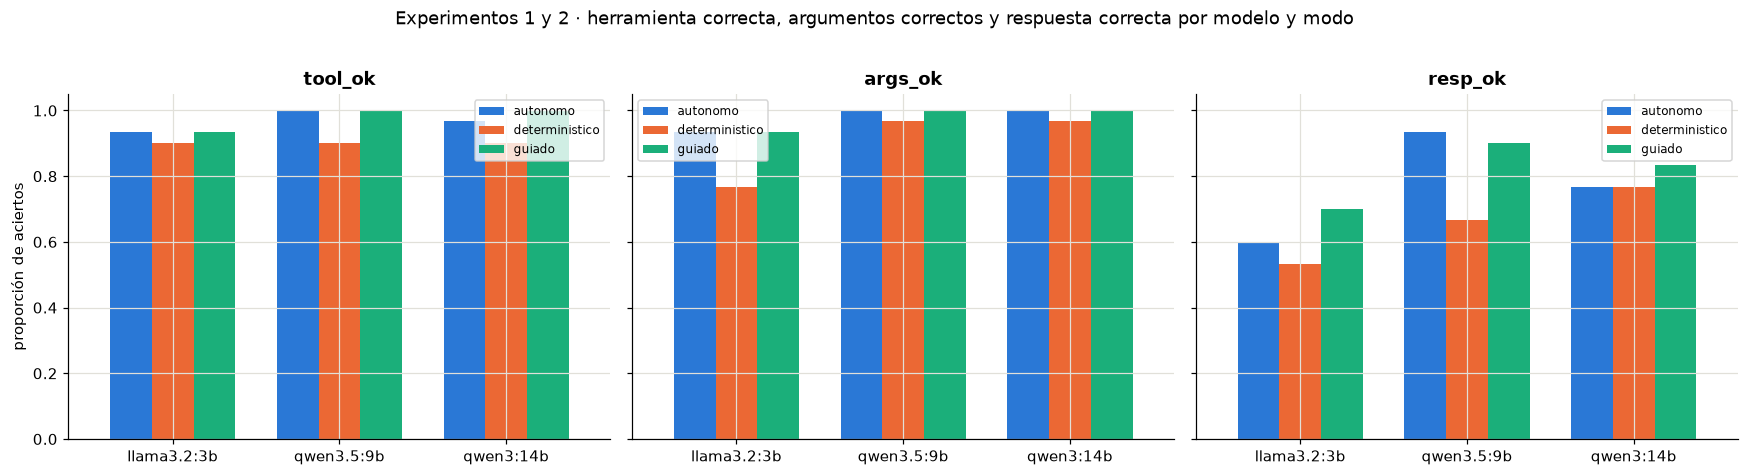

In [20]:
df = pd.read_csv(CSV)
base = df[(df.tools == 'base') & (df.descripcion == 'completa')]
tabla12 = resumen(base, ['modelo', 'modo'])
display(tabla12)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, metrica in zip(axes, ['tool_ok', 'args_ok', 'resp_ok']):
    piv = base.pivot_table(index='modelo', columns='modo', values=metrica, aggfunc='mean').reindex(MODELOS)
    piv.plot.bar(ax=ax, color=[AZUL, NARANJA, VERDE], rot=0, width=.75)
    ax.set_title(metrica); ax.set_ylim(0, 1.05); ax.set_xlabel(''); ax.legend(fontsize=8)
axes[0].set_ylabel('proporción de aciertos')
plt.suptitle('Experimentos 1 y 2 · herramienta correcta, argumentos correctos y respuesta correcta por modelo y modo', y=1.02)
plt.tight_layout(); plt.savefig(ROOT / 'figuras' / 'exp12_modelo_modo.png', bbox_inches='tight'); plt.show()

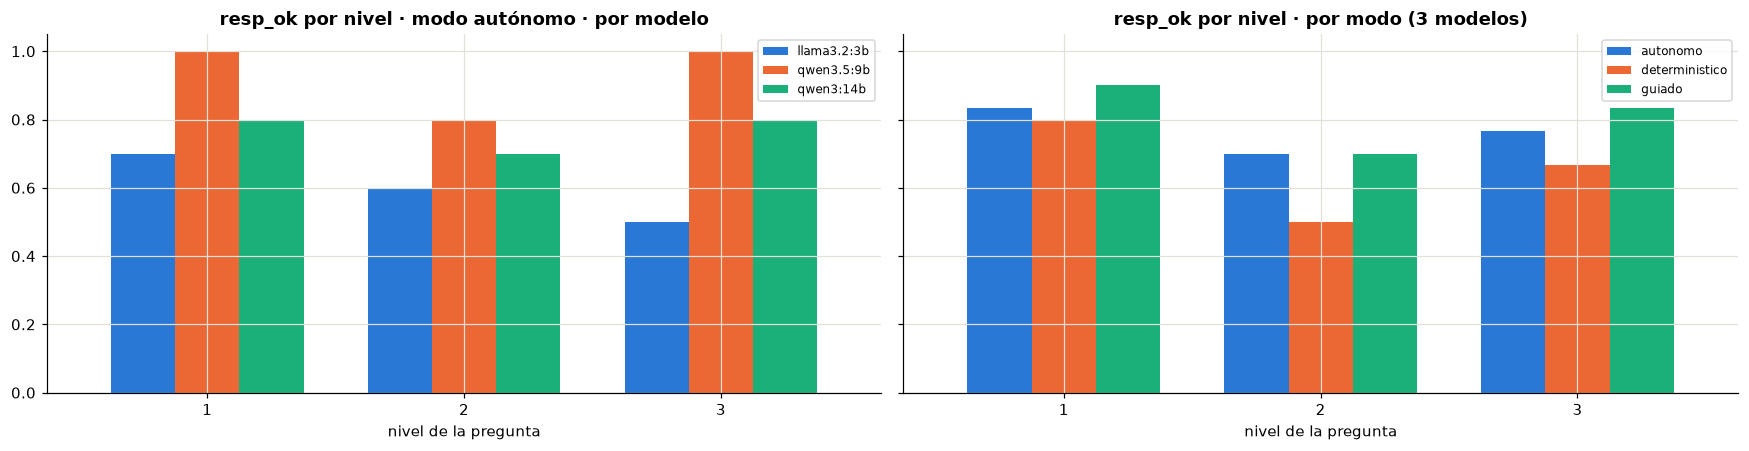

tool_ok  args_ok  resp_ok  llamadas  latencia_s   n
modo           nivel                                                     
autonomo       1        0.933    0.967    0.833     0.933       4.233  30
               2        0.967    0.967    0.700     1.533       4.640  30
               3        1.000    1.000    0.767     0.667       2.480  30
deterministico 1        1.000    0.933    0.800     1.000       3.110  30
               2        0.800    0.800    0.500     1.000       3.357  30
               3        0.900    0.967    0.667     0.900       2.557  30
guiado         1        0.967    0.967    0.900     1.067       5.680  30
               2        1.000    0.967    0.700     1.633       5.117  30
               3        0.967    1.000    0.833     0.833       3.703  30

In [21]:
# Por nivel de dificultad: ¿dónde se abre la brecha entre modelos y entre modos?
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), sharey=True)
piv = base[base.modo == 'autonomo'].pivot_table(index='nivel', columns='modelo', values='resp_ok', aggfunc='mean')[MODELOS]
piv.plot.bar(ax=axes[0], color=[AZUL, NARANJA, VERDE], rot=0, width=.75); axes[0].set_title('resp_ok por nivel · modo autónomo · por modelo')
piv = base.pivot_table(index='nivel', columns='modo', values='resp_ok', aggfunc='mean')
piv.plot.bar(ax=axes[1], color=[AZUL, NARANJA, VERDE], rot=0, width=.75); axes[1].set_title('resp_ok por nivel · por modo (3 modelos)')
for ax in axes: ax.set_ylim(0, 1.05); ax.set_xlabel('nivel de la pregunta'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(ROOT / 'figuras' / 'exp12_nivel.png'); plt.show()
display(resumen(base, ['modo', 'nivel']))

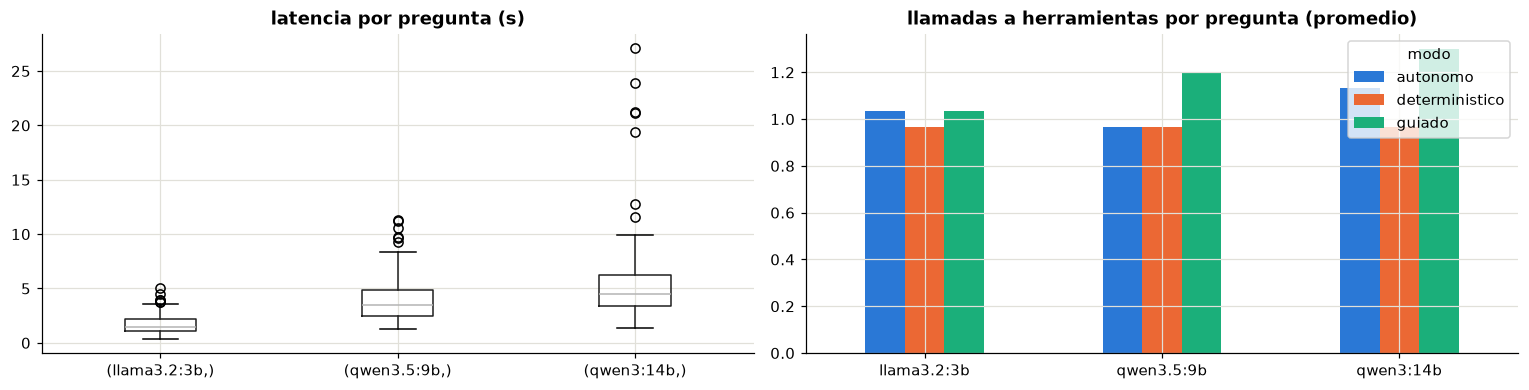

In [22]:
# Latencia y número de llamadas por modelo y modo
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
base.boxplot(column='latencia_s', by=['modelo'], ax=axes[0]); axes[0].set_title('latencia por pregunta (s)'); axes[0].set_xlabel('')
base.pivot_table(index='modelo', columns='modo', values='n_llamadas', aggfunc='mean').reindex(MODELOS).plot.bar(ax=axes[1], color=[AZUL, NARANJA, VERDE], rot=0)
axes[1].set_title('llamadas a herramientas por pregunta (promedio)'); axes[1].set_xlabel('')
plt.suptitle(''); plt.tight_layout(); plt.savefig(ROOT / 'figuras' / 'exp12_latencia.png'); plt.show()

**Lectura.** La brecha entre modelos aparece en `resp_ok` y deja casi intacta la elección de herramienta (`tool_ok` entre 90 % y 100 % en todas las celdas). En el modo autónomo el modelo de 3B cae de 70 % en el nivel 1 a 50 % en el nivel 3, el de 9B se mantiene entre 80 % y 100 % y el de 14B entre 70 % y 80 %. El modo determinístico pierde 30 a 40 puntos frente al autónomo en los niveles 2 y 3 del modelo de 9B. Las latencias medias del modo autónomo son 1.4 s, 4.3 s y 5.7 s para los modelos de 3B, 9B y 14B. Con 30 preguntas por celda el intervalo de confianza del 95 % mide cerca de ±15 puntos, de modo que 60 % frente a 93 % es una diferencia firme y 77 % frente a 93 % admite solapamiento.

### 11.2 Experimento 3: herramientas distractoras

tool_ok  args_ok  resp_ok  llamadas  latencia_s   n
modelo      tools                                                        
llama3.2:3b ampliado    0.900    0.933    0.667     1.133       1.493  30
            base        0.933    0.933    0.600     1.033       1.380  30
qwen3.5:9b  ampliado    0.967    1.000    0.967     1.000       4.970  30
            base        1.000    1.000    0.933     0.967       4.277  30
qwen3:14b   ampliado    0.967    1.000    0.833     1.200       6.370  30
            base        0.967    1.000    0.767     1.133       5.697  30

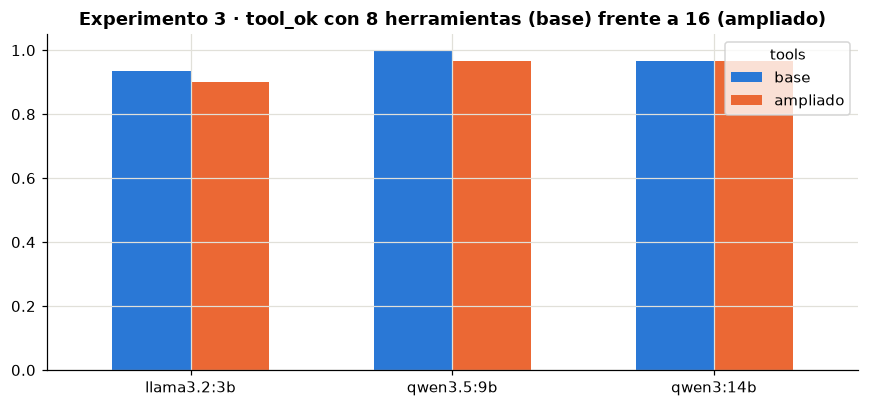

tools_usadas
sesiones_activas        1
buscar_documentacion    1
clima_actual            1
Name: veces llamada, dtype: int64

In [23]:
e3 = df[(df.modo == 'autonomo') & (df.descripcion == 'completa')]
tabla3 = resumen(e3, ['modelo', 'tools'])
display(tabla3)
fig, ax = plt.subplots(figsize=(8, 3.8))
e3.pivot_table(index='modelo', columns='tools', values='tool_ok', aggfunc='mean').reindex(MODELOS)[['base', 'ampliado']].plot.bar(ax=ax, color=[AZUL, NARANJA], rot=0, width=.6)
ax.set_ylim(0, 1.05); ax.set_title('Experimento 3 · tool_ok con 8 herramientas (base) frente a 16 (ampliado)'); ax.set_xlabel('')
plt.tight_layout(); plt.savefig(ROOT / 'figuras' / 'exp3_distractoras.png'); plt.show()
# ¿Qué distractoras se llamaron?
dist = e3[e3.tools == 'ampliado'].tools_usadas.str.split('+').explode()
display(dist[dist.isin([t.name for t in DISTRACTORAS])].value_counts().rename('veces llamada'))

**Lectura.** Con 16 herramientas disponibles `tool_ok` cambia de 93 % a 90 % en el modelo de 3B, de 100 % a 97 % en el de 9B y se mantiene en 97 % en el de 14B. Cada diferencia equivale a una pregunta de 30. Las distractoras se llamaron 3 veces en 90 corridas del modo autónomo: `sesiones_activas` y `buscar_documentacion` en el modelo de 3B y `clima_actual` en el de 9B. Las más tentadoras son las que comparten tema con el dominio.

### 11.3 Experimento 4: calidad de las descripciones

tool_ok  args_ok  resp_ok  llamadas  latencia_s   n
modelo      descripcion                                                     
llama3.2:3b completa       0.933    0.933    0.600     1.033       1.380  30
            minima         0.933    0.900    0.567     1.200       1.633  30
qwen3.5:9b  completa       1.000    1.000    0.933     0.967       4.277  30
            minima         0.933    0.900    0.767     1.100       4.473  30
qwen3:14b   completa       0.967    1.000    0.767     1.133       5.697  30
            minima         0.933    0.900    0.733     1.067       5.343  30

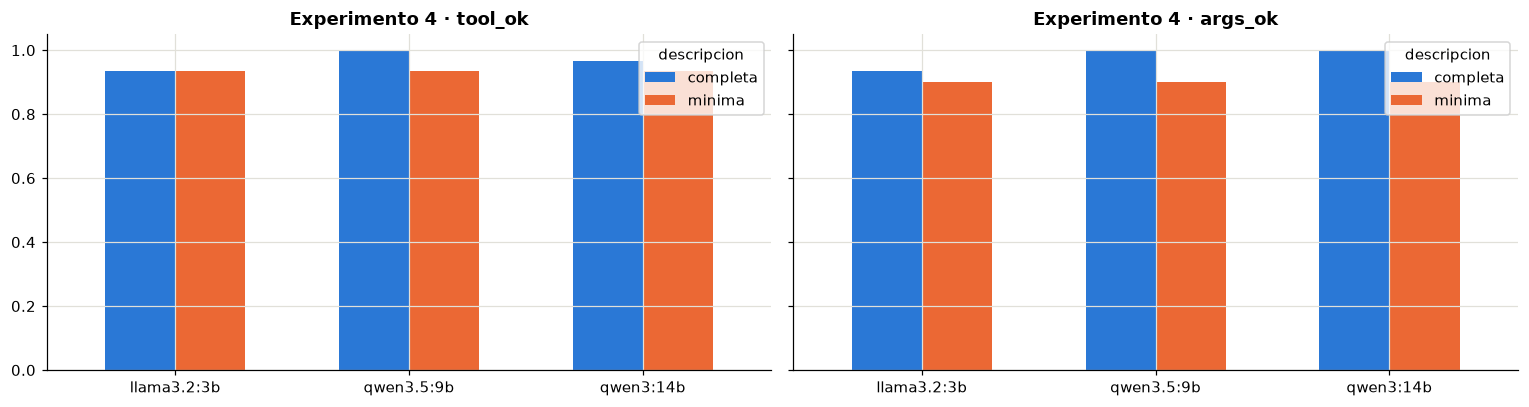

In [24]:
e4 = df[(df.modo == 'autonomo') & (df.tools == 'base')]
tabla4 = resumen(e4, ['modelo', 'descripcion'])
display(tabla4)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, metrica in zip(axes, ['tool_ok', 'args_ok']):
    e4.pivot_table(index='modelo', columns='descripcion', values=metrica, aggfunc='mean').reindex(MODELOS)[['completa', 'minima']].plot.bar(ax=ax, color=[AZUL, NARANJA], rot=0, width=.6)
    ax.set_ylim(0, 1.05); ax.set_title(f'Experimento 4 · {metrica}'); ax.set_xlabel('')
plt.tight_layout(); plt.savefig(ROOT / 'figuras' / 'exp4_descripciones.png'); plt.show()

**Lectura.** Con descripciones mínimas `tool_ok` baja entre 0 y 7 puntos y `args_ok` baja 7 puntos en el modelo de 3B y 10 en los de 9B y 14B. La caída se concentra en las preguntas que dependen de valores de dominio que solo la descripción completa enumera, como el filtro `tipo` de `backups_recientes` (N1-06 y N1-10). En `resp_ok` el modelo de 9B pasa de 93 % a 77 %. El modelo sabe qué herramienta llamar por el nombre; los argumentos exactos los aprende de la descripción.

### 11.4 Errores típicos: leer las respuestas falladas

Las métricas dicen cuánto falla cada configuración; las respuestas dicen cómo. Mostramos una muestra de fallos por tipo.

In [25]:
pd.set_option('display.max_colwidth', 160)
fallos = df[(df.tools == 'base') & (df.descripcion == 'completa')]
print('Herramienta equivocada o ausente:')
display(fallos[~fallos.tool_ok][['modelo', 'modo', 'id', 'tools_usadas', 'respuesta']].head(6))
print('Herramienta correcta, argumentos equivocados:')
display(fallos[fallos.tool_ok & ~fallos.args_ok][['modelo', 'modo', 'id', 'llamadas']].head(6))
print('Herramienta y argumentos correctos, respuesta incorrecta (cifra mal copiada o conclusión equivocada):')
display(fallos[fallos.tool_ok & fallos.args_ok & ~fallos.resp_ok][['modelo', 'modo', 'id', 'respuesta']].head(6))
print('Errores de ejecución:')
display(fallos[fallos.error.notna() & (fallos.error != '')][['modelo', 'modo', 'id', 'error']].head(6))

Herramienta equivocada o ausente:


,modelo,modo,id,tools_usadas,respuesta
9,llama3.2:3b,autonomo,N1-10,-,"{""name"":""rman_jobs"",""parameters"":{""base"":""BSSPROD19"",""job_id"":null,""tipo"":null,""inicio"":null,""fin"":null,""estado"":null,""gb"":null,""mensaje"":null}}"
19,llama3.2:3b,autonomo,N2-10,proyeccion_llenado,"El tablespace AUDIT_DATA de BSSPROD19 bajó de tamaño en algún momento, específicamente el 2026-12-21, cuando se llenaría en aproximadamente 68 días. El nive..."
39,llama3.2:3b,guiado,N1-10,-,"{""name"":""rman_jobs"",""parameters"":{""base"":""BSSPROD19"",""job_id"":null,""tipo"":null,""inicio"":null,""fin"":null,""estado"":null,""gb"":null,""mensaje"":null}}"
59,llama3.2:3b,guiado,N3-10,estado_fra,"Lo siento, pero no puedo proporcionar información sobre la Fast Recovery Area sin conocer la base de datos específica en la que se encuentra. La Fast Recove..."
72,llama3.2:3b,deterministico,N2-03,estado_fra,"Lo siento, pero no puedo proporcionar información sobre el estado de la FRA o el backup específico de RACBSS19 el 27 de septiembre. El error de estado_fra i..."
77,llama3.2:3b,deterministico,N2-08,rpo_actual,"Para realizar la revisión diaria de RACBSS19, he consultado las herramientas de Oracle. A continuación, te presento los resultados:\n\n**RPO de RACBSS19**\n..."


Herramienta correcta, argumentos equivocados:


,modelo,modo,id,llamadas
10,llama3.2:3b,autonomo,N2-01,"[{""name"": ""proyeccion_llenado"", ""args"": {""base"": ""SFPROD18"", ""tablespace"": ""(SELECT name FROM dba_tablespaces WHERE status='ONLINE' AND creation_date > (SYS..."
40,llama3.2:3b,guiado,N2-01,"[{""name"": ""proyeccion_llenado"", ""args"": {""tablespace"": ""(SELECT name FROM dba_tablespaces WHERE status='ONLINE' AND creation_date > (SYSDATE - 365)) ORDER B..."
63,llama3.2:3b,deterministico,N1-04,"[{""name"": ""estado_fra"", ""args"": {""base"": {""description"": ""RACBSS19"", ""title"": ""Base"", ""type"": ""string""}}}]"
64,llama3.2:3b,deterministico,N1-05,"[{""name"": ""rpo_actual"", ""args"": {""base"": {""description"": ""Nombre de la base de datos: SFPROD18, BSSPROD19, BSSSTBY19 o RACBSS19."", ""title"": ""Base"", ""type"": ..."
70,llama3.2:3b,deterministico,N2-01,"[{""name"": ""proyeccion_llenado"", ""args"": {""base"": {""description"": ""SFPROD18"", ""title"": ""Base"", ""type"": ""string""}, ""tablespace"": {""description"": ""Nombre del t..."
73,llama3.2:3b,deterministico,N2-04,"[{""name"": ""rpo_actual"", ""args"": {""base"": {""description"": ""SFPROD18"", ""title"": ""Base"", ""type"": ""string""}}}]"


Herramienta y argumentos correctos, respuesta incorrecta (cifra mal copiada o conclusión equivocada):


,modelo,modo,id,respuesta
5,llama3.2:3b,autonomo,N1-06,Los backups FULL de RACBSS19 en los últimos 30 días son los siguientes:\n\n* El backup del 11 de octubre de 2026 a las 02:00:00 tiene un tamaño de 2915.3 GB...
7,llama3.2:3b,autonomo,N1-08,"Lo siento, pero no tengo información sobre backups fallidos en SFPROD18. Sin embargo, puedo proporcionarte información sobre los backups recientes y los bac..."
12,llama3.2:3b,autonomo,N2-03,El backup FULL de RACBSS19 el 27 de septiembre falló porque no se encontró un snapshot disponible para el backup. La FRA de RACBSS19 al día siguiente mostra...
18,llama3.2:3b,autonomo,N2-09,"Según los eventos de espera de RACBSS19, el día 1 de octubre de 2026, el log file sync tuvo 4283 segundos de tiempo de espera."
21,llama3.2:3b,autonomo,N3-02,"Para obtener el RPO de BSSSTBY19, debemos consultar el valor de `rpo_actual('BSSSTBY19')`:\n\n```\nSELECT rpo_actual('BSSSTBY19') FROM DUAL;\n```\n\nLa resp..."
24,llama3.2:3b,autonomo,N3-05,"{""type"":""function"",""function"":{""name"":""backups_recientes"",""parameters"":{""base"":""SFPROD18"",""dias"":7,""tipo"":""ARCHIVELOG""}}"


Errores de ejecución:


,modelo,modo,id,error


**Lectura.** Los fallos con herramienta y argumentos correctos son los más frecuentes en los tres modelos. Tienen tres orígenes: una base asumida sin que la pregunta la nombre (`¿Cuál es el crecimiento de USERS?` se respondió sobre BSSPROD19, donde USERS no existe), una conclusión que contradice la cifra devuelta (AUDIT_DATA con crecimiento de +5.8 GB y a la vez "no ha bajado") y una limitación de las herramientas (no existe un filtro por estado de backup, de modo que `Muéstrame los backups que fallaron` obliga a inventar un parámetro). Las dos primeras dependen del modelo y la tercera del diseño del servidor.

## 12. Demo: el asistente en Gradio

`app_gradio.py` monta el mismo agente en una interfaz de chat con selector de modelo, modo y conjunto de herramientas, y muestra
la **traza MCP** (herramienta, argumentos y salida) debajo de cada respuesta. Esa traza es la que permite a un DBA confiar en la
respuesta: ve de dónde salió cada cifra. Se puede lanzar desde aquí o con `python app_gradio.py` en una terminal.

In [16]:
from app_gradio import demo
demo.launch(inline=False, prevent_thread_lock=True)
# demo.close()   # para liberar el puerto 7860

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## 13. Conclusiones

1. **Tamaño del modelo (exp. 1).** La elección de la herramienta es alta en los tres modelos (`tool_ok` autónomo de 93 %, 100 % y 97 % para 3B, 9B y 14B) y los argumentos también (`args_ok` de 93 %, 100 % y 100 %). La diferencia aparece al usar la salida de la herramienta: `resp_ok` de 60 %, 93 % y 77 %. En el modelo de 3B la brecha crece con la dificultad (70 %, 60 % y 50 % por nivel). La hipótesis 1 se cumple para el modelo de 3B frente al de 9B. El de 14B queda por debajo del de 9B, y como los tres modelos pertenecen a familias y versiones distintas (Llama 3.2, Qwen 3.5 y Qwen 3), el experimento no separa tamaño de familia. La única pregunta que fallaron los tres en el modo autónomo es N2-09 (día con más espera por `log file sync`).
2. **Modo de ejecución (exp. 2).** El modo guiado obtiene el mayor `resp_ok` en el modelo de 3B (70 % frente a 60 %) y en el de 14B (83 % frente a 77 %), y queda tres puntos por debajo del autónomo en el de 9B (90 % frente a 93 %), a cambio de más llamadas (1.2 a 1.3 por pregunta frente a 1.0 a 1.1). El determinístico fija `tool_ok` en 90 % para los tres modelos y reduce `args_ok` a 77 % en el de 3B, que extrae mal la base cuando la pregunta no la nombra. En el modelo de 9B baja `resp_ok` a 50 % y 60 % en los niveles 2 y 3, frente a 80 % y 100 % del autónomo. La hipótesis 2 se cumple en su segunda mitad: el determinístico no supera al autónomo en las preguntas simples (60 %, 90 % y 90 % en el nivel 1 frente a 70 %, 100 % y 80 %) y pierde en las compuestas. Su ventaja es la latencia en los modelos grandes (mediana de 2.8 s y 3.6 s frente a 3.8 s y 4.9 s).
3. **Herramientas distractoras (exp. 3).** Con 16 herramientas `tool_ok` cambia de 93 % a 90 %, de 100 % a 97 % y se mantiene en 97 % para 3B, 9B y 14B. Son diferencias de una pregunta. Las distractoras se llamaron 3 veces en 90 corridas (`sesiones_activas`, `buscar_documentacion` y `clima_actual`). La hipótesis 3 no se confirma con estos datos: ocho herramientas de más no degradan de forma apreciable la elección en modelos de 3B a 14B. El efecto, si existe, es menor que la resolución del banco.
4. **Descripciones (exp. 4).** Con descripciones mínimas `tool_ok` baja de 0 a 7 puntos, `args_ok` baja de 7 a 10 puntos y `resp_ok` baja 3, 16 y 4 puntos en 3B, 9B y 14B. `args_ok` cae más que `tool_ok`: los modelos eligen la herramienta por su nombre y completan los argumentos con lo que dice la descripción. La hipótesis 4 se confirma en la dirección, con una magnitud menor a la esperada para `tool_ok`. Las preguntas afectadas son las que usan filtros con valores fijos (`tipo` en `backups_recientes`).
5. **Transporte (exp. 5).** En la corrida del Mac streamable HTTP tuvo una mediana de 2.2 ms (p95 2.5 ms) y stdio de 1.4 ms (p95 1.7 ms), con un arranque de 0.68 s para stdio; frente a latencias del modelo de 1 a 6 s,
   el transporte no decide el rendimiento. stdio conviene para un servidor que vive junto al cliente; HTTP, para un servidor
   compartido por varios hosts, que es el caso de un equipo de DBA.
6. **Diseño del servidor.** Las salidas compactas, los errores que listan las opciones válidas y el enrutador por palabras clave
   son decisiones baratas que cambian lo que el modelo puede hacer. El *resource* y el *prompt* muestran que MCP es más que
   "funciones remotas": el servidor también publica contexto y plantillas de uso.
7. **Mínimo privilegio.** La base en solo lectura y el *authorizer* de SQL hacen que el peor error del modelo sea una consulta
   inútil. Es la misma regla que aplicaría a un usuario humano de reportes y la condición para conectar este agente a una base real.
8. **Límites.** Datos sintéticos con escenarios plantados; un calificador por fragmentos de texto que marca como fallida una respuesta correcta con otra redacción (N1-10 espera `2026-10-14` y el modelo escribió "14 de octubre de 2026"; normalizando fechas, `resp_ok` del modelo de 14B sube de 3 a 4 puntos);
   30 preguntas por celda, con intervalos de confianza de cerca de ±15 puntos; `temperature=0` en una sola corrida, sin varianza entre corridas; tres
   modelos de familias y versiones distintas (Llama 3.2, Qwen 3.5 y Qwen 3, estos dos con el razonamiento desactivado), de modo que el tamaño y la familia van juntos. Para producción harían falta datos reales por una conexión de solo lectura,
   un juez más fino (por ejemplo, otro LLM que compare cifras) y varias semillas por configuración.

### Siguientes pasos

- Conectar el servidor a `GV$`/`DBA_` reales mediante una cuenta de solo lectura, con `AUDIT` unificado sobre esa cuenta.
- Añadir un *resource* por base con su historial de cambios (CHG) para que el agente explique causas, no solo síntomas.
- Un modo "revisión diaria" programado que use el *prompt* del servidor y envíe el informe por correo.
- Un juez basado en LLM que califique las respuestas abiertas de nivel 2.

### Referencias

- Anthropic (2024). *Model Context Protocol — Specification*. https://modelcontextprotocol.io
- LangChain (2025). *MCP Adapters* y *create_agent*. https://docs.langchain.com
- Yao et al. (2023). *ReAct: Synergizing Reasoning and Acting in Language Models*. ICLR.
- Schick et al. (2023). *Toolformer: Language Models Can Teach Themselves to Use Tools*. NeurIPS.
- Sen, P. K. (1968). *Estimates of the regression coefficient based on Kendall's tau*. JASA (estimador de Theil-Sen).
- Oracle (2024). *Database Backup and Recovery User's Guide*, 19c (FRA, RPO, RMAN).
- Notebooks guía del curso: https://github.com/Ohtar10/icesi-nlp (Sesion6).